# Graduate Admission Prediction Using ANN

**Goal:** Build an Artificial Neural Network (ANN) to predict a graduate applicant's chance of admission from academic and profile features.

This notebook uses a commonly shared `Admission_Predict.csv` dataset. Place the CSV in the same folder as this notebook. The target column is usually `Chance of Admit`; common input columns include GRE Score, TOEFL Score, University Rating, SOP, LOR, CGPA, and Research.

> This is a learning demonstration, not a tool for making real admissions decisions. Predictions may reflect bias or limitations in the historical data.

## 1. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load and inspect the dataset

Download or obtain `Admission_Predict.csv` and put it beside this notebook. If your filename or target column differs, update the path or target name below.

In [8]:
DATA_PATH = "Admission_Predict.csv"
df = pd.read_csv(DATA_PATH)

# Remove accidental whitespace from column names.
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())
print("\\nMissing values per column:\\n", df.isna().sum())

Dataset shape: (40, 9)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


\nColumns: ['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']
\nMissing values per column:\n Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


## 3. Clean the data and select features

The original dataset often contains a serial-number column named `Serial No.`. It is an identifier, so we remove it. Missing rows are dropped for this simple baseline.

In [9]:
TARGET = "Chance of Admit"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. Available columns: {df.columns.tolist()}"
    )

df = df.drop(columns=["Serial No."], errors="ignore")
df = df.dropna().copy()

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(float)

# The expected dataset is numeric. Convert columns if they contain numeric strings.
X = X.apply(pd.to_numeric, errors="raise")

print("Feature columns:", X.columns.tolist())
print("Rows after cleaning:", len(df))
display(df.describe().T)

Feature columns: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
Rows after cleaning: 40


,count,mean,std,min,25%,50%,75%,max
GRE Score,40.0,316.8750,11.152067,295.00,309.50,317.500,324.2500,340.00
TOEFL Score,40.0,107.2500,6.307301,93.00,102.75,107.500,110.2500,120.00
University Rating,40.0,3.2000,1.114013,1.00,2.75,3.000,4.0000,5.00
SOP,40.0,3.4625,0.894338,1.50,3.00,3.500,4.0000,5.00
LOR,40.0,3.3125,0.882069,1.50,3.00,3.000,4.0000,5.00
CGPA,40.0,8.4890,0.623069,7.20,8.00,8.450,8.8775,9.80
Research,40.0,0.5500,0.503831,0.00,0.00,1.000,1.0000,1.00
Chance of Admit,40.0,0.7035,0.137011,0.44,0.62,0.685,0.7850,0.97


## 4. Split into training and test sets

We keep the test set separate so evaluation reflects data the model did not train on. The scaler is fitted only on training features to prevent data leakage.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 32
Test rows: 8


## 5. Build the ANN

This is a regression task because the target is a continuous admission-chance estimate. The output layer therefore has one neuron and no activation function.

In [11]:
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.15),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model

Early stopping helps stop training when validation loss no longer improves and restores the best weights.

In [12]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=300,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - loss: 0.2517 - mae: 0.4542 - val_loss: 0.1667 - val_mae: 0.3385
Epoch 2/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - loss: 0.2480 - mae: 0.4517 - val_loss: 0.1352 - val_mae: 0.2957
Epoch 3/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - loss: 0.1681 - mae: 0.3495 - val_loss: 0.1154 - val_mae: 0.2537
Epoch 4/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 543ms/step - loss: 0.1101 - mae: 0.2766 - val_loss: 0.1060 - val_mae: 0.2213
Epoch 5/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - loss: 0.1105 - mae: 0.2899 - val_loss: 0.1022 - val_mae: 0.2205
Epoch 6/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - loss: 0.1419 - mae: 0.2988 - val_loss: 0.0975 - val_mae: 0.2143
Epoch 7/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - loss: 0.0940 - mae: 0.2594 - val_loss: 0.0910 - val_mae: 0.2066
Epoch 8/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - loss: 0.0795 - mae: 0.2290 - val_loss: 0.0837 - val_mae: 0.1985
Epoch 9/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - loss: 0.0747 - ma

## 7. Plot training history

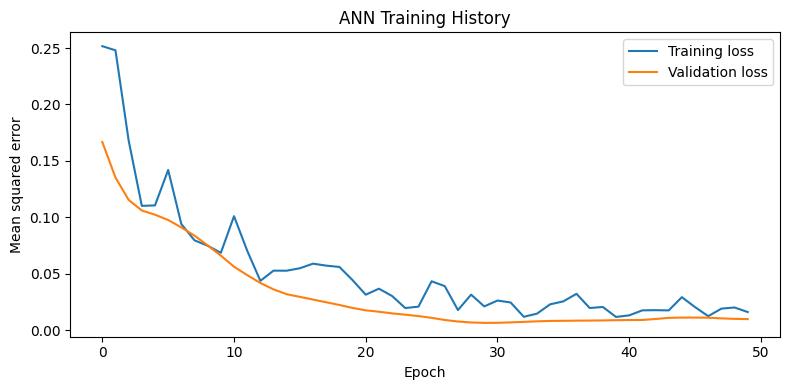

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("ANN Training History")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Evaluate on the test set

MAE and RMSE are easier to interpret when compared with the target scale. R² measures how much variation is explained by the model; it can be negative if predictions are poor.

In [14]:
y_pred = model.predict(X_test_scaled, verbose=0).ravel()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.1703
RMSE: 0.2037
R²:   -3.3968


## 9. Actual vs predicted values

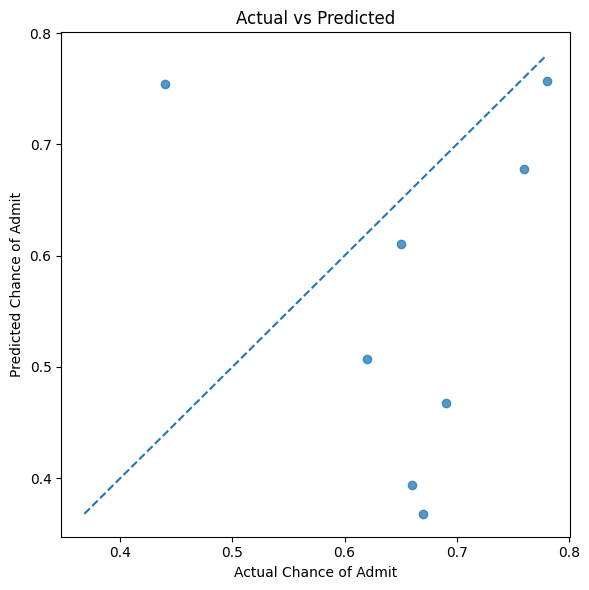

,Actual,Predicted
0,0.62,0.507074
1,0.66,0.393736
2,0.67,0.367994
3,0.76,0.677913
4,0.65,0.610095
5,0.78,0.757227
6,0.69,0.467527
7,0.44,0.754171


In [15]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.75)
low = min(float(y_test.min()), float(y_pred.min()))
high = max(float(y_test.max()), float(y_pred.max()))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Chance of Admit")
plt.ylabel("Predicted Chance of Admit")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.show()

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
display(results.head(10))

## 10. Predict for a new applicant

Enter values in the same feature order and with the same meaning/scale as the dataset. The code below uses the first test row as a safe example. Replace it with a new applicant's feature values when ready.

In [16]:
# Example prediction using an existing held-out row.
sample = X_test.iloc[[0]]
sample_scaled = scaler.transform(sample)
predicted_chance = float(model.predict(sample_scaled, verbose=0)[0][0])

print("Input features:")
display(sample)
print(f"Predicted Chance of Admit: {predicted_chance:.3f}")

Input features:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
19,303,102,3,3.5,3.0,8.5,0


Predicted Chance of Admit: 0.507


## 11. Save the trained model and scaler

The scaler is needed at prediction time. Save both so new data receives the same preprocessing.

In [17]:
model.save("graduate_admission_ann.keras")

import joblib
joblib.dump(scaler, "admission_scaler.joblib")

print("Saved model: graduate_admission_ann.keras")
print("Saved scaler: admission_scaler.joblib")

Saved model: graduate_admission_ann.keras
Saved scaler: admission_scaler.joblib


## Conclusion

- The notebook loads and cleans admission data.
- It standardizes input features and trains an ANN regressor.
- It evaluates predictions using MAE, RMSE, and R².
- It saves the model and scaler for later experiments.

**Important:** Results depend on the dataset, its quality, and the train/test split. Do not use this small educational model as the sole basis for actual admissions decisions.